# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart choice:** Line chart (indexed time series, 1970 = 100).

**Justification:**
- **Why this chart:** The question asks for growth over time *relative to 1970 size*. A standard line chart of raw population would be dominated by Asia's sheer size. Indexing each continent to 100 in 1970 aligns their starting points so the slopes directly show relative growth speed.
- **Design choices:** I used an intentional focal palette: Africa is highlighted in bold blue (`#0284c7`) with a heavier line width (3.5 vs 1.8), while all other continents are muted in neutral slate grey (`#94a3b8`). Direct end labels at 2022 remove the need for a separate legend, and a dotted baseline marks the 1970 starting level (100).

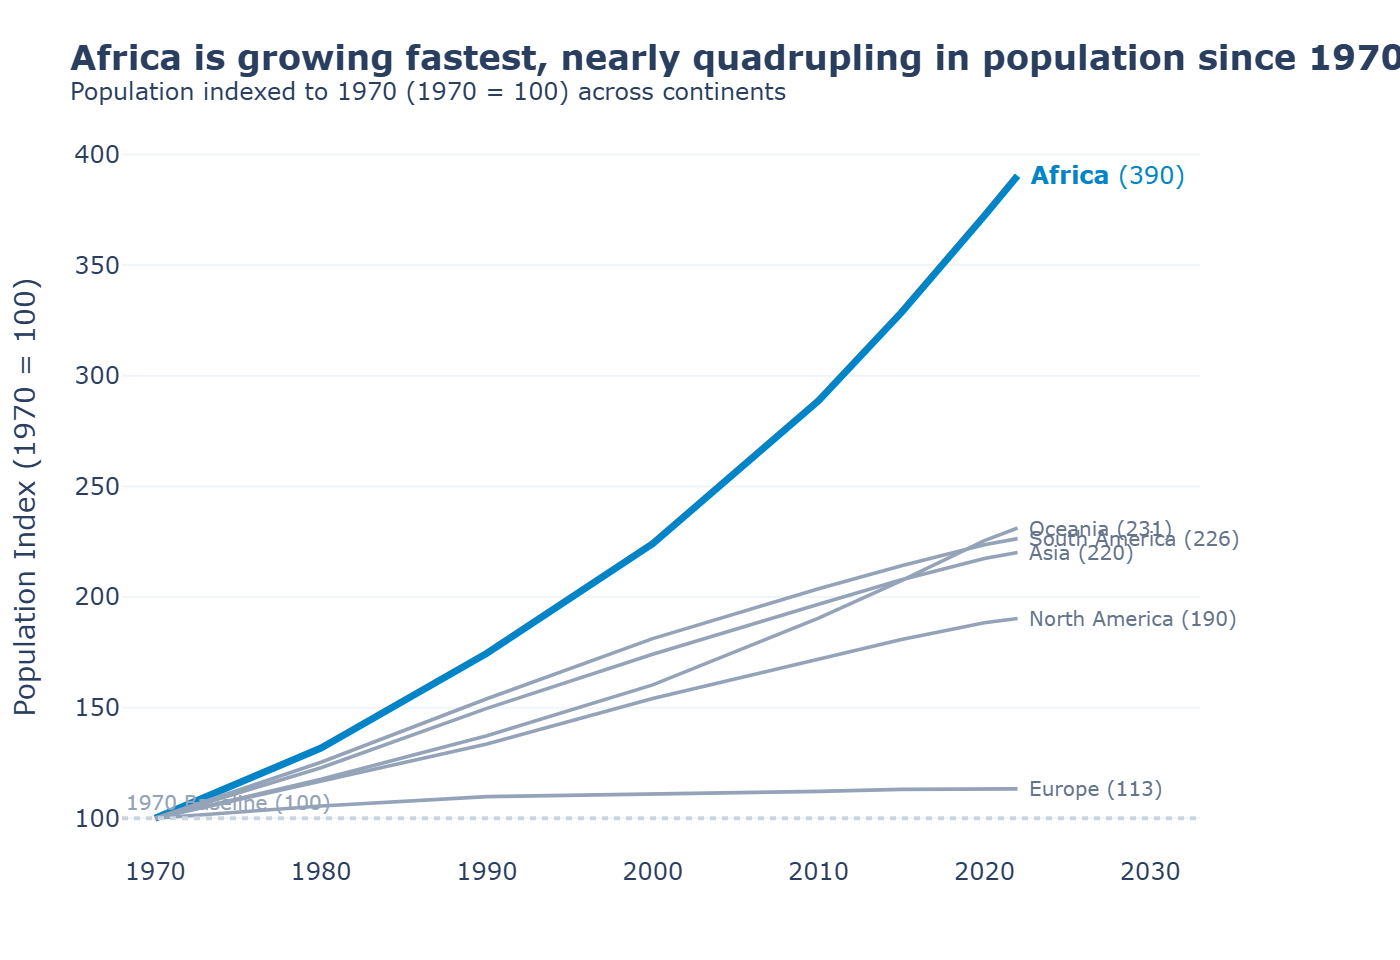

In [ ]:
# Q1: 
cont = df_long.groupby(['Continent', 'Year'])['Population'].sum().reset_index()
pop_1970 = cont[cont['Year'] == 1970].set_index('Continent')['Population']
cont['Index'] = (cont['Population'] / cont['Continent'].map(pop_1970)) * 100

colors_q1 = {c: '#94a3b8' for c in cont['Continent'].unique()}
colors_q1['Africa'] = '#0284c7'

fig1 = px.line(
    cont, x='Year', y='Index', color='Continent',
    color_discrete_map=colors_q1,
    title="<b>Africa is growing fastest, nearly quadrupling in population since 1970 (+290%)</b><br><sup>Population indexed to 1970 (1970 = 100) across continents</sup>"
)

for trace in fig1.data:
    if trace.name == 'Africa':
        trace.line.width = 3.5
    else:
        trace.line.width = 1.8

for continent in cont['Continent'].unique():
    row_2022 = cont[(cont['Continent'] == continent) & (cont['Year'] == 2022)].iloc[0]
    val = row_2022['Index']
    is_africa = (continent == 'Africa')
    txt = f" <b>{continent}</b> ({val:.0f})" if is_africa else f" {continent} ({val:.0f})"
    fig1.add_annotation(
        x=2022, y=val, text=txt,
        showarrow=False, xanchor='left', yanchor='middle',
        font=dict(color='#0284c7' if is_africa else '#64748b', size=12 if is_africa else 10)
    )


fig1.add_hline(
    y=100, line_dash='dot', line_color='#cbd5e1',
    annotation_text="1970 Baseline (100)", annotation_position="top left",
    annotation_font_size=10, annotation_font_color='#94a3b8'
)

fig1.update_layout(
    template='plotly_white',
    showlegend=False,
    xaxis=dict(title='', dtick=10, showgrid=False, range=[1968, 2033]),
    yaxis=dict(title='Population Index (1970 = 100)', showgrid=True, gridcolor='#f1f5f9'),
    margin=dict(l=60, r=100, t=70, b=40),
    height=480
)

fig1.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart choice:** Sorted horizontal bar chart.

**Justification:**
- **Why this chart:** We are ranking a discrete top-15 list by a single quantitative metric (net people added from 1970 to 2022). Horizontal bars allow country names to be read naturally without angled text. Sorting ascending from bottom-to-top puts the leaders (India and China) prominently at the top.
- **Design choices:** Used a CVD-safe binary highlight: African countries (Nigeria, Ethiopia, DR Congo, Egypt) are highlighted in accent blue (`#0284c7`), while other countries are muted in soft grey (`#cbd5e1`). Direct outside value labels (`+860M`, etc.) make exact quantities instantly readable without gridline tracing.

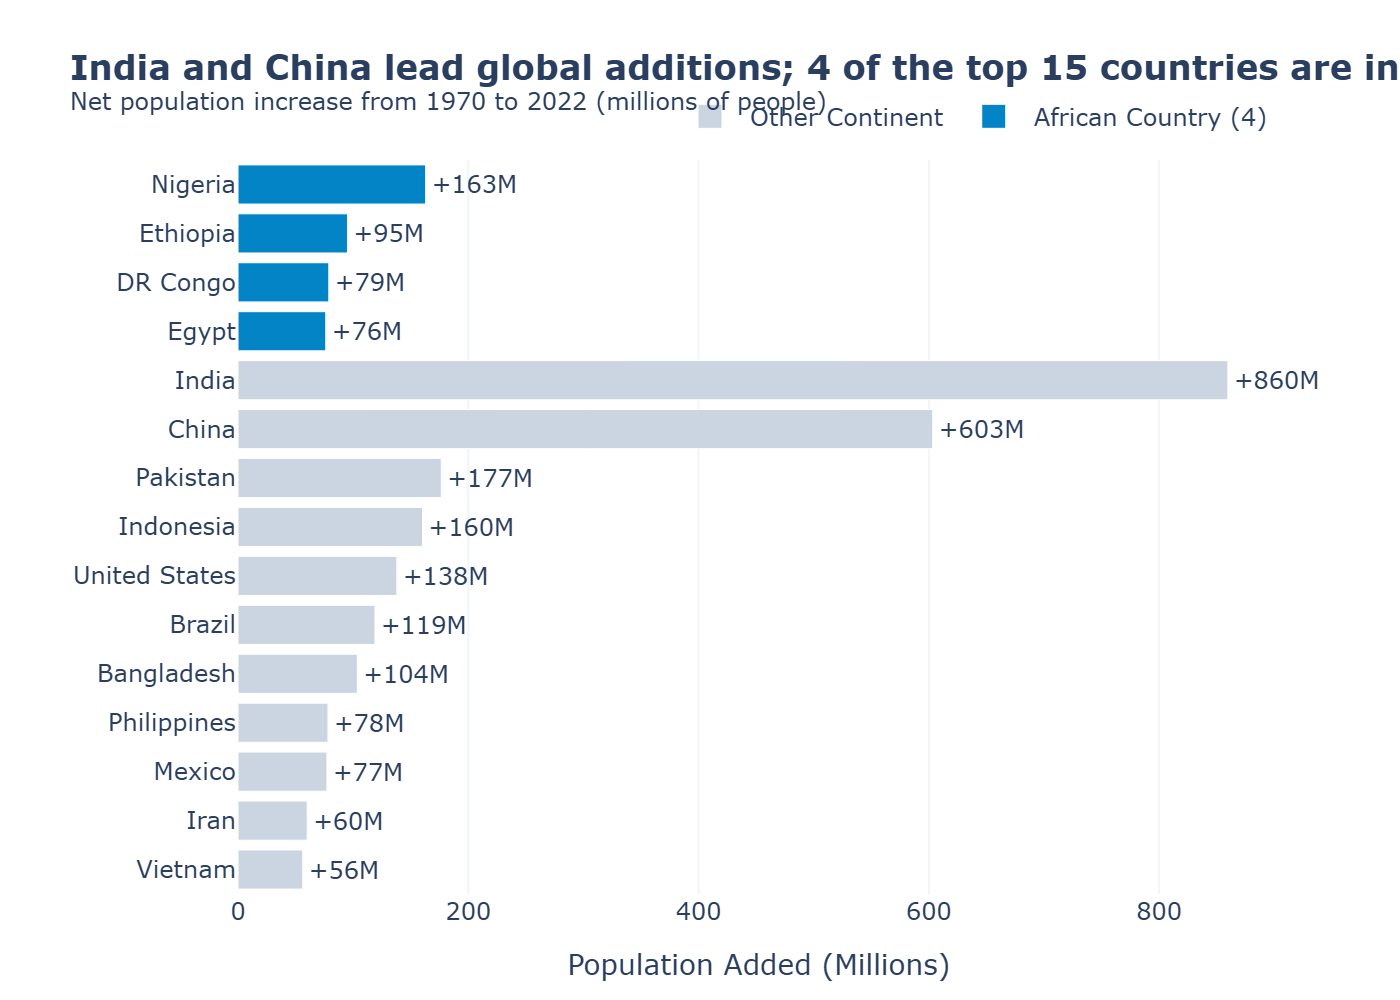

In [ ]:
# Q2:
df['Added'] = df['2022 Population'] - df['1970 Population']
top15 = df.nlargest(15, 'Added').sort_values('Added', ascending=True).copy()
top15['Added_M'] = top15['Added'] / 1e6
top15['Is_Africa'] = top15['Continent'].apply(lambda x: 'African Country (4)' if x == 'Africa' else 'Other Continent')

fig2 = px.bar(
    top15, x='Added_M', y='Country', color='Is_Africa',
    orientation='h',
    text=top15['Added_M'].apply(lambda v: f"+{v:.0f}M"),
    color_discrete_map={'African Country (4)': '#0284c7', 'Other Continent': '#cbd5e1'},
    title="<b>India and China lead global additions; 4 of the top 15 countries are in Africa</b><br><sup>Net population increase from 1970 to 2022 (millions of people)</sup>"
)

fig2.update_traces(textposition='outside', cliponaxis=False)

fig2.update_layout(
    template='plotly_white',
    xaxis=dict(title='Population Added (Millions)', showgrid=True, gridcolor='#f1f5f9', zeroline=False),
    yaxis=dict(title='', showgrid=False),
    legend=dict(title='', orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    margin=dict(l=80, r=60, t=80, b=40),
    height=500
)

fig2.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart choice:** Scatter plot (log-log scale).

**Justification:**
- **Why this chart:** The question examines the bivariate relationship between two continuous variables (land area vs 2022 population) and asks for specific outliers breaking the trend across continents.
- **Design choices:** Both land area and population span over 6 orders of magnitude (from microstates < 10 km² to Russia at 17M km²; Vatican City at 500 people to China at 1.4B). Log scales on both axes are essential to unclamp the data and reveal the underlying positive power-law relationship. Continents are encoded with a distinct CVD-safe palette. Direct annotations highlight the major pattern-breakers: China/India and Bangladesh far above trend, and Greenland, Australia, and Canada far below.

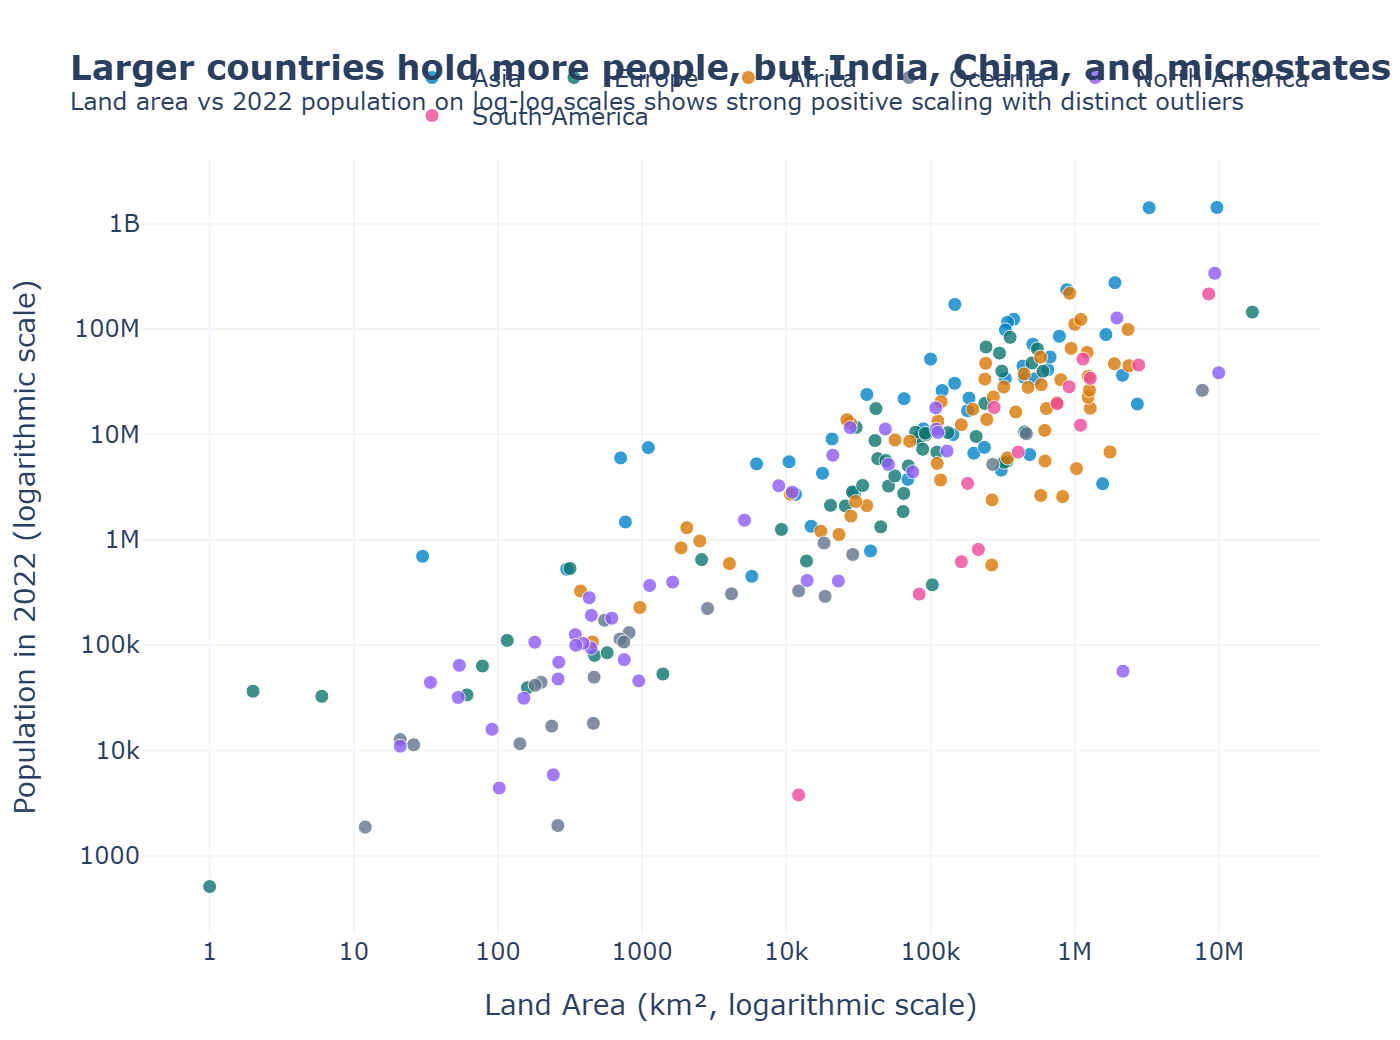

In [4]:
# Q3: 
palette_continents = {
    'Asia': '#0284c7',
    'Africa': '#d97706',
    'Europe': '#0f766e',
    'North America': '#8b5cf6',
    'South America': '#ec4899',
    'Oceania': '#64748b'
}

fig3 = px.scatter(
    df, x='Area', y='2022 Population', color='Continent',
    color_discrete_map=palette_continents,
    hover_name='Country',
    log_x=True, log_y=True,
    title="<b>Larger countries hold more people, but India, China, and microstates break the pattern</b><br><sup>Land area vs 2022 population on log-log scales shows strong positive scaling with distinct outliers</sup>"
)

fig3.update_traces(marker=dict(size=7, opacity=0.8, line=dict(width=0.5, color='#ffffff')))


outliers_q3 = [
    ('China', "China & India:<br>Huge population (>1.4B) far above trend", -20, -30),
    ('Singapore', "Singapore:<br>Extreme density (8.4k/km²)", 25, -25),
    ('Greenland', "Greenland:<br>Massive land (2.1M km²), only 56k people", -20, 25),
    ('Australia', "Australia:<br>Large continent, sparse", 20, 20),
    ('Bangladesh', "Bangladesh:<br>171M in compact area", -25, 20)
]

for country, label, ax, ay in outliers_q3:
    row = df[df['Country'] == country]
    if not row.empty:
        r = row.iloc[0]
        fig3.add_annotation(
            x=r['Area'], y=r['2022 Population'],
            text=label,
            showarrow=True, arrowhead=2, arrowsize=1, arrowwidth=1.2, arrowcolor='#475569',
            ax=ax, ay=ay,
            font=dict(size=9, color='#1e293b'),
            bgcolor='rgba(255,255,255,0.85)',
            bordercolor='#cbd5e1', borderwidth=0.8
        )

fig3.update_layout(
    template='plotly_white',
    xaxis=dict(title='Land Area (km², logarithmic scale)', showgrid=True, gridcolor='#f1f5f9'),
    yaxis=dict(title='Population in 2022 (logarithmic scale)', showgrid=True, gridcolor='#f1f5f9'),
    legend=dict(title='', orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    margin=dict(l=60, r=40, t=80, b=50),
    height=520
)

fig3.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart choice:** Box plot (with logarithmic y-axis).

**Justification:**
- **Why this chart:** The question asks how population density varies *within and across* continents and explicitly instructs to "show the spread, not just the average." A box plot displays medians, IQRs, whiskers, and isolated outliers simultaneously.
- **Design choices:** Population density is heavily skewed by microstates (e.g. Macau at 23,000+ /km², Monaco at 18,000+ /km²). A log scale (`log_y=True`) is mandatory so that the boxes of lower-density continents don't collapse into a single flat line. Continents are sorted by median density for fast ranking, and extreme microstate outliers are directly annotated.

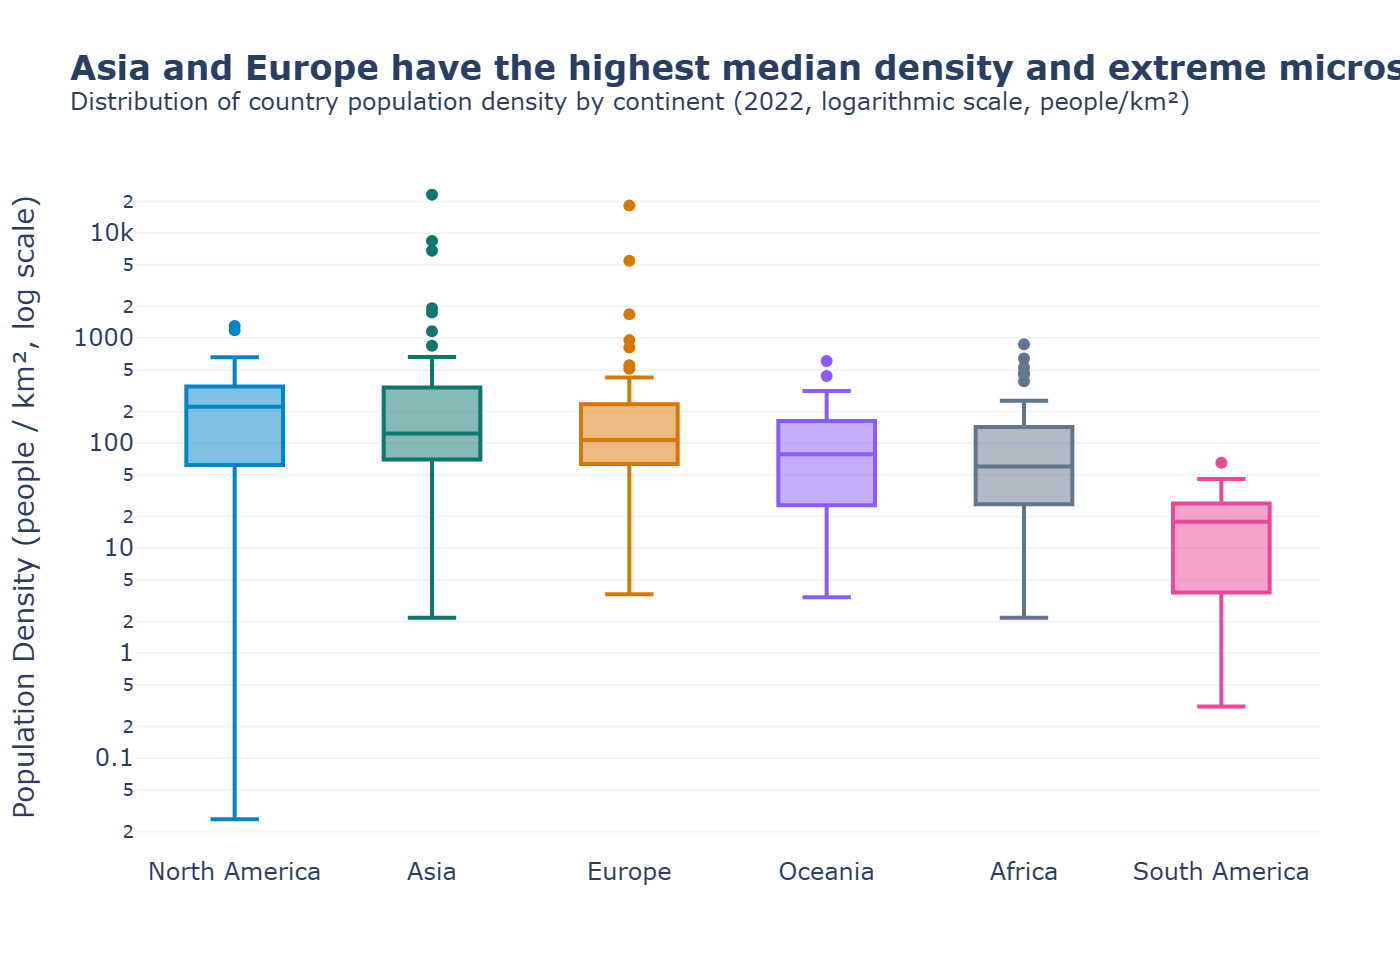

In [5]:
# Q4: 
continent_density_order = df.groupby('Continent')['Density'].median().sort_values(ascending=False).index.tolist()

fig4 = px.box(
    df, x='Continent', y='Density',
    category_orders={'Continent': continent_density_order},
    log_y=True,
    points='outliers',
    hover_name='Country',
    color='Continent',
    color_discrete_sequence=['#0284c7', '#0f766e', '#d97706', '#8b5cf6', '#64748b', '#ec4899'],
    title="<b>Asia and Europe have the highest median density and extreme microstate outliers</b><br><sup>Distribution of country population density by continent (2022, logarithmic scale, people/km²)</sup>"
)


macau = df[df['Country'] == 'Macau'].iloc[0]
monaco = df[df['Country'] == 'Monaco'].iloc[0]

fig4.add_annotation(
    x='Asia', y=float(macau['Density']),
    text="<b>Macau</b>: 23,172/km²",
    showarrow=True, arrowhead=2, arrowsize=1, ax=45, ay=-5,
    font=dict(size=9, color='#0284c7'), bgcolor='rgba(255,255,255,0.85)', bordercolor='#cbd5e1'
)
fig4.add_annotation(
    x='Europe', y=float(monaco['Density']),
    text="<b>Monaco</b>: 18,235/km²",
    showarrow=True, arrowhead=2, arrowsize=1, ax=45, ay=-5,
    font=dict(size=9, color='#0f766e'), bgcolor='rgba(255,255,255,0.85)', bordercolor='#cbd5e1'
)

fig4.update_layout(
    template='plotly_white',
    showlegend=False,
    xaxis=dict(title='', showgrid=False),
    yaxis=dict(title='Population Density (people / km², log scale)', showgrid=True, gridcolor='#f1f5f9'),
    margin=dict(l=60, r=40, t=80, b=40),
    height=480
)

fig4.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart choice:** Choropleth map.

**Justification:**
- **Why this chart:** The question specifically asks *"where in the world are they?"*, requiring geographic localization across countries. A choropleth map links percentage change directly to global ISO-3 country borders (`CCA3`), revealing spatial regional patterns that a bar chart or table would obscure.
- **Design choices:** Used a diverging CVD-safe color palette (`PuOr`: Purple-to-Orange) centered at 0% change (`color_continuous_midpoint=0`). Purple immediately signals population shrinkage (<0%), while orange tones indicate positive growth. Used a clean `natural earth` projection without a distracting bounding frame.

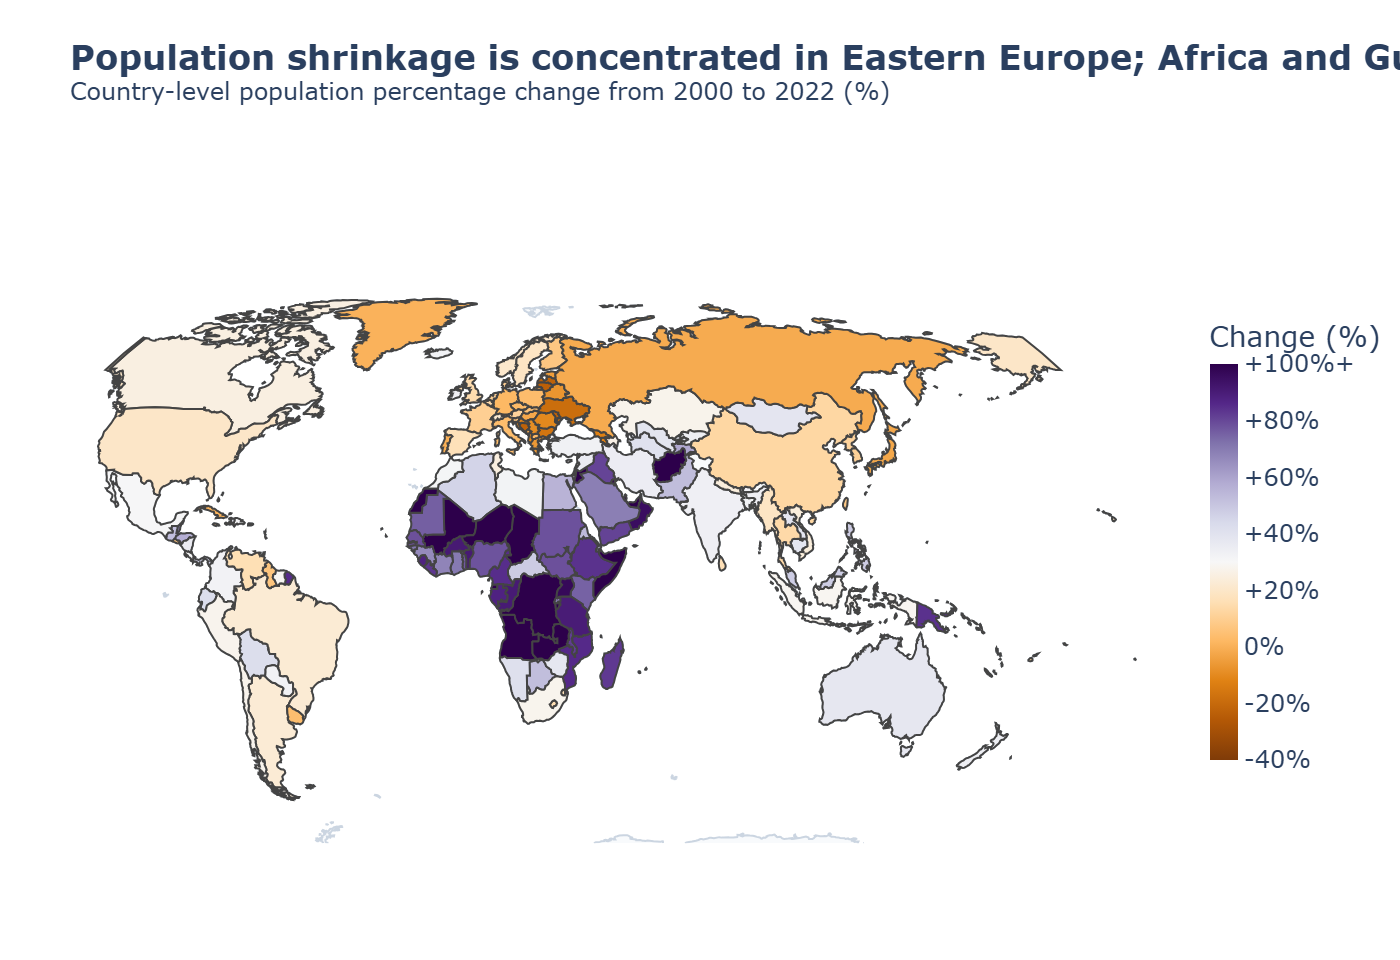

In [6]:
# Q5: 
df['Pct_Change_2000_2022'] = ((df['2022 Population'] - df['2000 Population']) / df['2000 Population']) * 100

fig5 = px.choropleth(
    df,
    locations='CCA3',
    locationmode='ISO-3',
    color='Pct_Change_2000_2022',
    hover_name='Country',
    hover_data={'CCA3': False, 'Pct_Change_2000_2022': ':.1f%'},
    color_continuous_scale='PuOr',
    color_continuous_midpoint=0,
    range_color=[-40, 100],
    title="<b>Population shrinkage is concentrated in Eastern Europe; Africa and Gulf States grew fastest</b><br><sup>Country-level population percentage change from 2000 to 2022 (%)</sup>"
)

fig5.update_geos(
    projection_type='natural earth',
    showcoastlines=True,
    coastlinecolor='#cbd5e1',
    showland=True,
    landcolor='#f8fafc',
    showocean=True,
    oceancolor='#ffffff',
    showlakes=False,
    showframe=False
)

fig5.update_layout(
    template='plotly_white',
    coloraxis_colorbar=dict(
        title='Change (%)',
        thickness=14,
        len=0.6,
        tickvals=[-40, -20, 0, 20, 40, 60, 80, 100],
        ticktext=['-40%', '-20%', '0%', '+20%', '+40%', '+60%', '+80%', '+100%+']
    ),
    margin=dict(l=0, r=0, t=70, b=10),
    height=480
)

fig5.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart choice:** Treemap.

**Justification:**
- **Why this chart:** The question asks how the world population is distributed across two hierarchical levels simultaneously: *continents and the countries within them*. A treemap is the ideal visual encoding for nested part-to-whole proportions, allocating rectangular area proportional to population size.
- **Design choices:** Nested hierarchy set to `path=['Continent', 'Country']`. Continents are assigned distinct CVD-safe hues so that countries within each continent form a cohesive visual block. Labels display country name and share of continent, making India and China's dominance in Asia immediately visible at a glance.


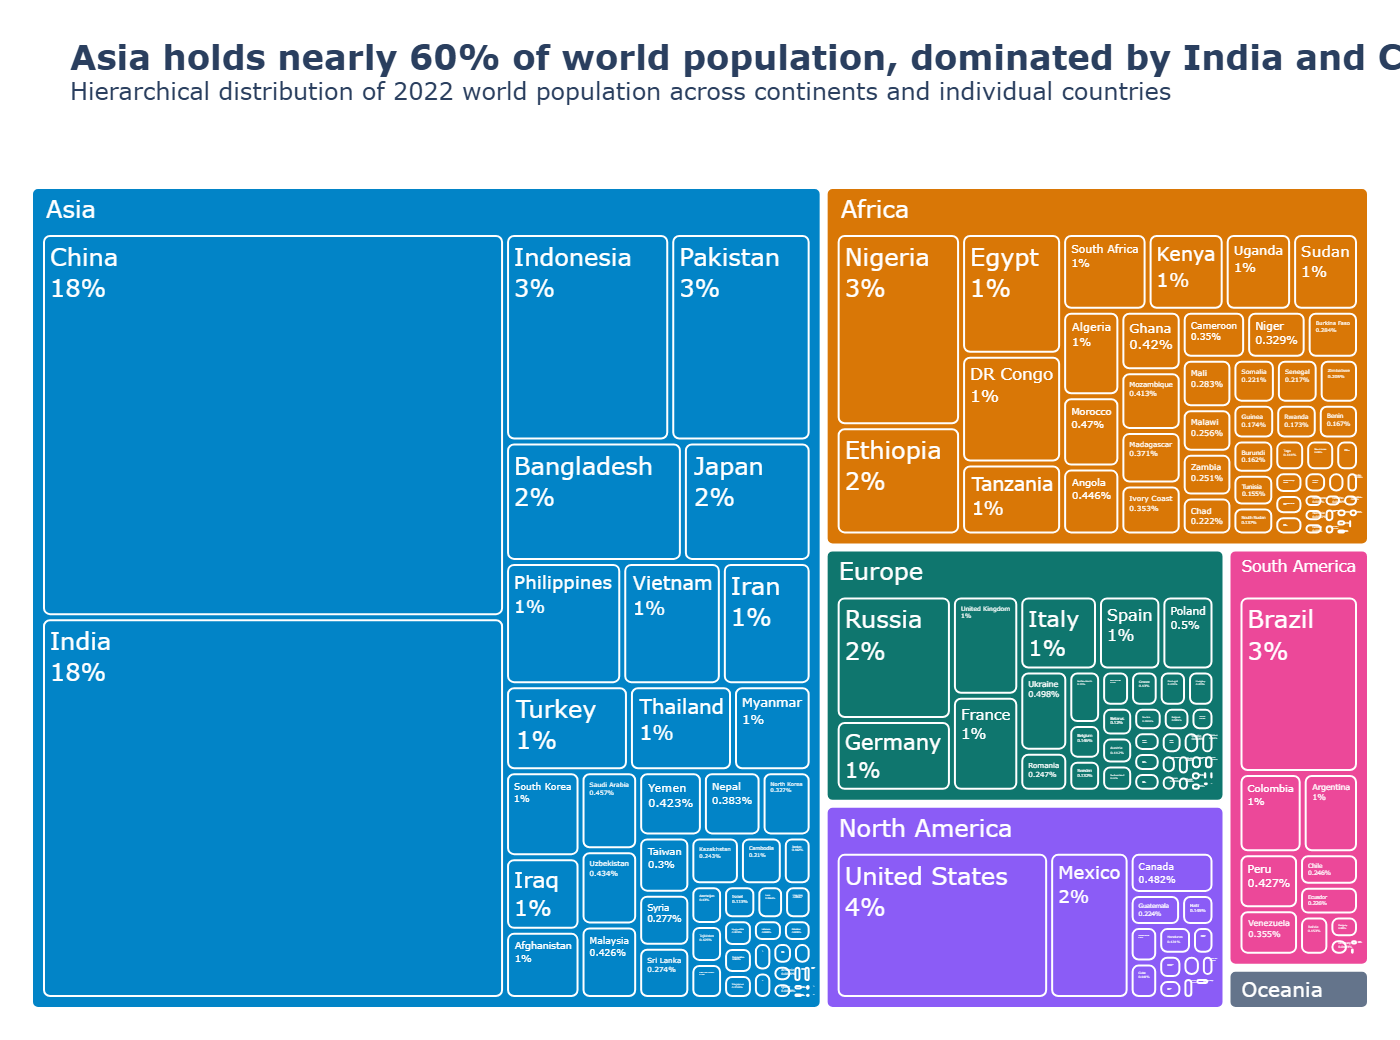

In [7]:
# Q6: 
fig6 = px.treemap(
    df,
    path=['Continent', 'Country'],
    values='2022 Population',
    color='Continent',
    color_discrete_map=palette_continents,
    title="<b>Asia holds nearly 60% of world population, dominated by India and China</b><br><sup>Hierarchical distribution of 2022 world population across continents and individual countries</sup>"
)

fig6.update_traces(
    textinfo='label+percent entry',
    marker=dict(cornerradius=3)
)

fig6.update_layout(
    template='plotly_white',
    margin=dict(l=10, r=10, t=70, b=10),
    height=520
)

fig6.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart choice:** 100% stacked bar chart.

**Justification:**
- **Why this chart:** The question asks how the regional *shares* of world population changed over time across discrete census years (1970–2022). A 100% stacked bar chart keeps the total bar height fixed at 100% for each year, making compositional shifts across regions immediately apparent.
- **Design choices:** CVD-safe palette with deliberate semantic color choices: rising Africa is highlighted in accent blue (`#0284c7`), declining Europe in amber (`#d97706`), dominant Asia in deep teal (`#0f766e`), and the grouped 'Rest of the world' in neutral slate grey (`#94a3b8`). In-bar percentage labels make individual shares readable without eye-strain.

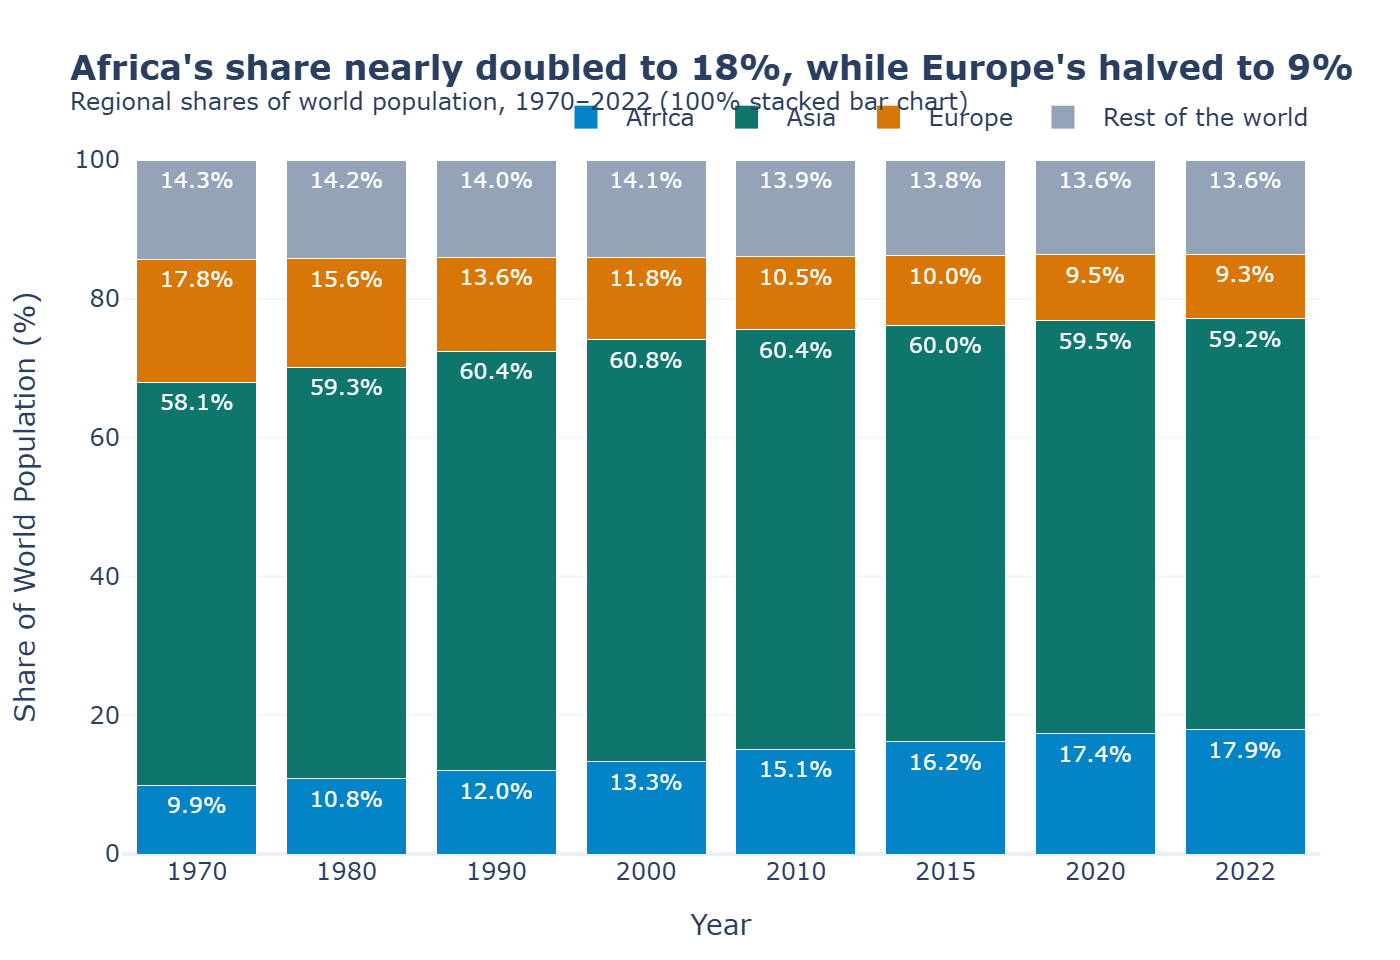

In [8]:
# Q7: Regional shares of world population over time (1970-2022)
df_long['Region'] = df_long['Continent'].apply(
    lambda c: c if c in ['Africa', 'Asia', 'Europe'] else 'Rest of the world'
)
share_df = df_long.groupby(['Year', 'Region'])['Population'].sum().reset_index()
tot = share_df.groupby('Year')['Population'].transform('sum')
share_df['Share'] = (share_df['Population'] / tot) * 100

order_q7 = ['Africa', 'Asia', 'Europe', 'Rest of the world']
share_df['Region'] = pd.Categorical(share_df['Region'], categories=order_q7, ordered=True)
share_df = share_df.sort_values(['Year', 'Region'])

share_df['Label'] = share_df['Share'].apply(lambda s: f"{s:.1f}%")
share_df['Year_Str'] = share_df['Year'].astype(str)

palette_q7 = {
    'Africa': '#0284c7',          # accent blue (rising)
    'Asia': '#0f766e',            # teal (majority)
    'Europe': '#d97706',          # amber (declining)
    'Rest of the world': '#94a3b8'# slate grey (context)
}

fig7 = px.bar(
    share_df, x='Year_Str', y='Share', color='Region',
    text='Label',
    category_orders={'Region': order_q7},
    color_discrete_map=palette_q7,
    title="<b>Africa's share nearly doubled to 18%, while Europe's halved to 9%</b><br><sup>Regional shares of world population, 1970–2022 (100% stacked bar chart)</sup>"
)

fig7.update_traces(
    textposition='inside',
    textfont=dict(size=11, color='white')
)

fig7.update_layout(
    template='plotly_white',
    barmode='stack',
    xaxis=dict(title='Year', showgrid=False),
    yaxis=dict(title='Share of World Population (%)', range=[0, 100], showgrid=True, gridcolor='#f1f5f9'),
    legend=dict(title='', orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    margin=dict(l=60, r=40, t=80, b=40),
    height=480
)

fig7.show()